Import libraries and load datasets

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [8]:
destinations = pd.read_csv("../data/processed/cleaned_destinations.csv")

tourism = pd.read_csv("../data/processed/cleaned_tourism_statistics.csv")

reviews = pd.read_csv("../data/processed/cleaned_tourist_reviews.csv")

print("Destinations:", destinations.shape)
print("Tourism:", tourism.shape)
print("Reviews:", reviews.shape)

Destinations: (33264, 33)
Tourism: (5241, 5)
Reviews: (20491, 5)


Choose our first ML model

Prepare the review data

In [10]:
# Select input and target
X = reviews["text"]
y = reviews["sentiment"]

# Check the data
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSentiment Distribution:")
print(y.value_counts())

Input Shape: (20491,)
Target Shape: (20491,)

Sentiment Distribution:
sentiment
Positive    15093
Negative     3214
Neutral      2184
Name: count, dtype: int64


Split the dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16392,)
Testing Data: (4099,)


Text vectorization using TF-IDF

In [12]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

# Fit on training data and transform
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (16392, 5000)
Testing TF-IDF Shape: (4099, 5000)


Train the Logistic Regression model

In [13]:
# Create model
model = LogisticRegression(max_iter=1000)

# Train model
model.fit(X_train_tfidf, y_train)

print("Model Training Completed!")

Model Training Completed!


Model Evaluation

In [14]:
# Predict test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 86.19 %


In [15]:
# Predict test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 86.19 %


Classification Report

In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.81      0.76      0.79       643
     Neutral       0.56      0.21      0.30       437
    Positive       0.89      0.98      0.93      3019

    accuracy                           0.86      4099
   macro avg       0.75      0.65      0.67      4099
weighted avg       0.84      0.86      0.84      4099



Confusion Matrix

NameError: name 'plt' is not defined

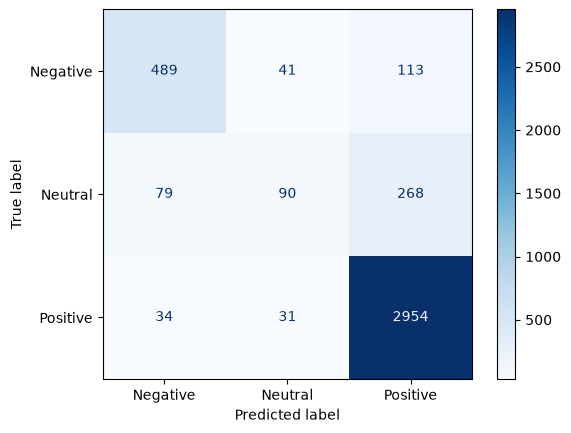

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues")
plt.title("Sentiment Classification Confusion Matrix")
plt.show()

Save the trained model

In [18]:
import joblib
import os

Create a models folder and save both files

In [19]:
os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/sentiment_model.pkl")

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and Vectorizer Saved Successfully!")

Model and Vectorizer Saved Successfully!


Test the saved model

In [20]:
# Load saved model and vectorizer
loaded_model = joblib.load("../models/sentiment_model.pkl")
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

# New review
new_review = ["The hotel was beautiful and the service was excellent"]

# Convert text into numbers
review_vector = loaded_tfidf.transform(new_review)

# Predict sentiment
prediction = loaded_model.predict(review_vector)

print("Review:", new_review[0])
print("Predicted Sentiment:", prediction[0])

Review: The hotel was beautiful and the service was excellent
Predicted Sentiment: Positive
